# code_139 · Conditional variational learning with mixed output likelihoods

**Book:** section 27.2. A self-contained generative-model laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_27_GUIDE.md), [run evidence](../CHAPTER_27_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_139).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=3339;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
import torch
from torch import nn
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS['torch']=torch.__version__
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 3339


<a id="conditional-vae-contract"></a>
 ## A likelihood must match each output type
 Eighty generated buildings each provide sixteen records, with source50/development15/final15 whole-building cohorts. A chosen operating regime c has prevalence0.15 and changes latent mode frequencies. Two latent physical drivers generate four continuous log load/response summaries, a binary alarm and an integer event count. Only continuous fields are source-standardized for the Gaussian likelihood; encoder inputs additionally include the binary value and log1p(count). A native conditional VAE uses two latent dimensions, Gaussian posterior reparameterization and Gaussian/Bernoulli/Poisson decoder heads. Beta0.1/1/8 recipes each receive1,400 Adam updates at0.003 and identical source minibatch schedules. A common beta-one development ELBO with four fixed noise draws chooses each checkpoint and then a recipe. Final data never select it. No mechanics or differential-privacy guarantee is implied by valid output types.


,beta,development_negative_ELBO_common_beta1,best_update,final_negative_ELBO_common_beta1,final_KL_per_latent,decoder_latent_mean_variance_condition1,parameters
0,0.1,4.613810,500,4.676657,"[3.0005026384639404, 3.459203520110447]",0.591148,846
1,1.0,3.692331,1050,3.764764,"[0.9734334138278707, 2.1198767555877036]",0.812088,846
2,8.0,6.160236,1050,6.300767,"[9.704663376960133e-05, 0.0014074060702904928]",0.011501,846


,beta,condition,reference_records,generated_records,generated_first_log_summary_tail_gt2_5,reference_tail_gt2_5,generated_alarm_rate,reference_alarm_rate,generated_count_mean,reference_count_mean
0,0.1,0,208,1000,0.018,0.028846,0.440,0.336538,1.653,1.533654
1,0.1,1,32,1000,0.085,0.281250,0.738,0.750000,2.505,3.093750
2,1.0,0,208,1000,0.014,0.028846,0.368,0.336538,1.504,1.533654
3,1.0,1,32,1000,0.122,0.281250,0.750,0.750000,2.585,3.093750
4,8.0,0,208,1000,0.012,0.028846,0.338,0.336538,1.540,1.533654
5,8.0,1,32,1000,0.153,0.281250,0.726,0.750000,2.748,3.093750


Selected beta from common development bound: 1.0


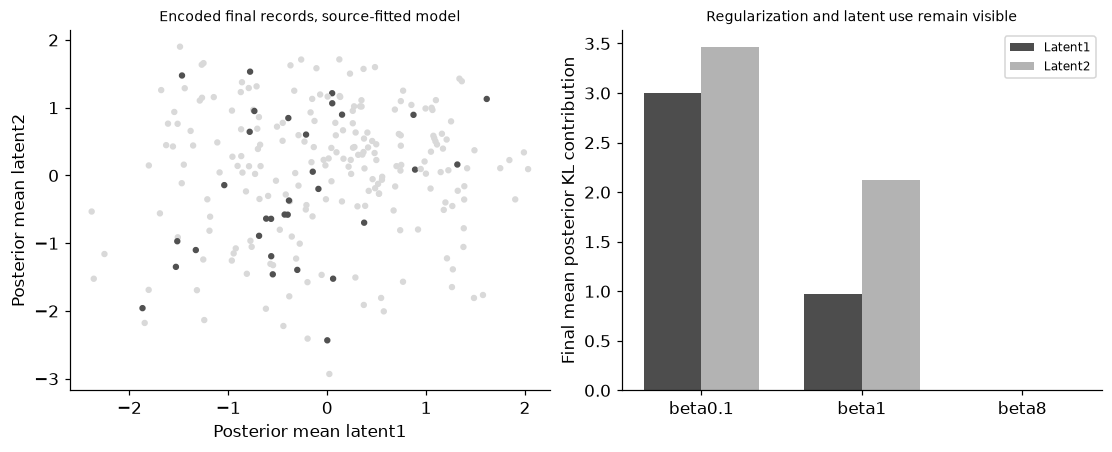

In [2]:
import copy
from scipy.special import expit
B,R=80,16;building=np.repeat(np.arange(B),R);condition=rng.binomial(1,.15,B*R);mode=rng.binomial(1,.2+.3*condition);offset=rng.normal(0,.15,B);q=rng.normal(0,.5,B*R)+1.8*mode+.6*condition+offset[building];r=.4*q+rng.normal(0,.5,B*R);continuous=np.column_stack([q,.7*q+.5*r,.4*q-.2*r,r])+rng.normal(0,.15,(B*R,4));alarm=rng.binomial(1,expit(1.2*(q-1)+.5*condition));count=rng.poisson(np.exp(.3+.25*q+.3*condition));source=building<50;development=(building>=50)&(building<65);final=building>=65;center=continuous[source].mean(0);spread=continuous[source].std(0);logjac=float(np.log(spread).sum());normalized=(continuous-center)/spread;encoder=np.column_stack([normalized,alarm,np.log1p(count),condition]);X=torch.tensor(encoder);Y=torch.tensor(normalized);C=torch.tensor(condition[:,None]).double();A=torch.tensor(alarm).double();K=torch.tensor(count).double();si=torch.tensor(np.flatnonzero(source));di=torch.tensor(np.flatnonzero(development));fi=torch.tensor(np.flatnonzero(final));orders=[si[torch.tensor(rng.choice(len(si),128,replace=False))] for _ in range(1400)];dev_eps=torch.tensor(rng.normal(size=(4,len(di),2)))
class ConditionalVAE(nn.Module):
    def __init__(self):super().__init__();self.encoder=nn.Sequential(nn.Linear(7,32),nn.Tanh(),nn.Linear(32,4));self.decoder=nn.Sequential(nn.Linear(3,32),nn.Tanh(),nn.Linear(32,10))
    def posterior(self,x):h=self.encoder(x);return h[:,:2],h[:,2:].clamp(-6,3)
    def decode(self,z,c):h=self.decoder(torch.cat([z,c],1));return h[:,:4],h[:,4:8].clamp(-3,2),h[:,8],h[:,9].clamp(-4,4)
def loss_terms(model,indices,epsilon=None):
    mu,lv=model.posterior(X[indices]);epsilon=torch.randn_like(mu) if epsilon is None else epsilon;z=mu+torch.exp(.5*lv)*epsilon;m,ls,logit,lr=model.decode(z,C[indices]);gaussian=(.5*((Y[indices]-m)/torch.exp(ls))**2+ls+.5*np.log(2*np.pi)).sum(1);bernoulli=torch.nn.functional.binary_cross_entropy_with_logits(logit,A[indices],reduction='none');poisson=torch.exp(lr)-K[indices]*lr+torch.lgamma(K[indices]+1);kl=.5*(mu**2+torch.exp(lv)-lv-1);return gaussian+bernoulli+poisson,kl
prior_mu=torch.zeros((3,2));prior_logvariance=torch.zeros_like(prior_mu)
torch.testing.assert_close(.5*(prior_mu**2+torch.exp(prior_logvariance)-prior_logvariance-1),torch.zeros_like(prior_mu))
models={};rows=[];best_overall=np.inf
for beta in [.1,1.,8.]:
    torch.manual_seed(SEED);model=ConditionalVAE();optimizer=torch.optim.Adam(model.parameters(),lr=.003);best=np.inf
    for step,indices in enumerate(orders,1):
        optimizer.zero_grad();reconstruction,kl=loss_terms(model,indices);loss=(reconstruction+beta*kl.sum(1)).mean();loss.backward();optimizer.step()
        if step%50==0:
            with torch.no_grad():score=float(torch.stack([(lambda terms:(terms[0]+terms[1].sum(1)).mean())(loss_terms(model,di,eps)) for eps in dev_eps]).mean())+logjac
            if score<best:best=score;state=copy.deepcopy(model.state_dict());best_step=step
    model.load_state_dict(state);models[beta]=model
    with torch.no_grad():
        mu,lv=model.posterior(X[fi]);kl=.5*(mu**2+torch.exp(lv)-lv-1);final_eps=torch.tensor(rng.normal(size=(4,len(fi),2)));final_nll=float(torch.stack([(lambda terms:(terms[0]+terms[1].sum(1)).mean())(loss_terms(model,fi,eps)) for eps in final_eps]).mean())+logjac;z_probe=torch.tensor(rng.normal(size=(1000,2)));decoded_mean=model.decode(z_probe,torch.ones((1000,1)))[0];sensitivity=float(decoded_mean.var(0,unbiased=False).mean())
    rows.append({'beta':beta,'development_negative_ELBO_common_beta1':best,'best_update':best_step,'final_negative_ELBO_common_beta1':final_nll,'final_KL_per_latent':kl.mean(0).tolist(),'decoder_latent_mean_variance_condition1':sensitivity,'parameters':sum(p.numel() for p in model.parameters())})
    if best<best_overall:best_overall=best;selected_beta=beta
generated={};coverage=[]
for beta,model in models.items():
    records=[]
    for c in [0,1]:
        with torch.no_grad():
            z=torch.tensor(rng.normal(size=(1000,2)));m,ls,logit,lr=model.decode(z,torch.full((1000,1),float(c)));normal=m+torch.exp(ls)*torch.tensor(rng.normal(size=(1000,4)));binary=torch.bernoulli(torch.sigmoid(logit));counts=torch.poisson(torch.exp(lr));values=normal.numpy()*spread+center
        assert np.all(np.isin(binary.numpy(),[0,1])) and np.all(counts.numpy()>=0) and np.all(counts.numpy()==np.floor(counts.numpy()))
        actual=final&(condition==c);coverage.append({'beta':beta,'condition':c,'reference_records':int(actual.sum()),'generated_records':1000,'generated_first_log_summary_tail_gt2_5':float(np.mean(values[:,0]>2.5)),'reference_tail_gt2_5':float(np.mean(continuous[actual,0]>2.5)),'generated_alarm_rate':float(binary.mean()),'reference_alarm_rate':float(alarm[actual].mean()),'generated_count_mean':float(counts.mean()),'reference_count_mean':float(count[actual].mean())});records.append((values,binary.numpy(),counts.numpy()))
    generated[beta]=records
RESULTS.update(comparisons=rows,conditional_generation=coverage,selected_beta=selected_beta,building_counts=[50,15,15],record_counts=[int(source.sum()),int(development.sum()),int(final.sum())],source_rare_condition_records=int((source&(condition==1)).sum()),final_rare_condition_records=int((final&(condition==1)).sum()),continuous_source_log_jacobian=logjac,latent_dimensions=2,updates_per_beta=1400);display(pd.DataFrame(rows));display(pd.DataFrame(coverage));print('Selected beta from common development bound:',selected_beta)
fig,axes=plt.subplots(1,2,figsize=(10,4));selected=models[selected_beta]
with torch.no_grad():mu,_=selected.posterior(X[fi])
axes[0].scatter(mu[:,0],mu[:,1],c=condition[final],cmap='Greys',vmin=-.5,vmax=1.5,s=10);axes[0].set(xlabel='Posterior mean latent1',ylabel='Posterior mean latent2',title='Encoded final records, source-fitted model');xx=np.arange(3)
for j,shade in enumerate(['.3','.7']):axes[1].bar(xx+(.18 if j else -.18),[row['final_KL_per_latent'][j] for row in rows],.36,color=shade,label=f'Latent{j+1}')
axes[1].set(xticks=xx,xticklabels=['beta0.1','beta1','beta8'],ylabel='Final mean posterior KL contribution',title='Regularization and latent use remain visible');axes[1].legend(fontsize=8);plt.show()


<a id="mixed-generation-and-collapse"></a>
 ## Type-valid sampling is only one acceptance check
 Decoder Gaussian means and scales describe standardized continuous observations; the fixed source log-Jacobian is included when reporting a common natural-unit negative ELBO. Bernoulli and Poisson heads sample binary and integer values directly. Likelihoods make conditional-independence assumptions given latent state/regime, rather than guaranteeing the entire mixed joint distribution is correct. Every beta recipe retains its own common development score, final per-latent KL and decoder sensitivity. Low KL and weak latent sensitivity can indicate collapse or unused capacity; neither is assumed solely from a large beta. The rare-regime reference count is reported rather than treating its few tail events as precise population prevalence. A good reconstruction score or valid count alone does not establish useful rare-scenario generation.


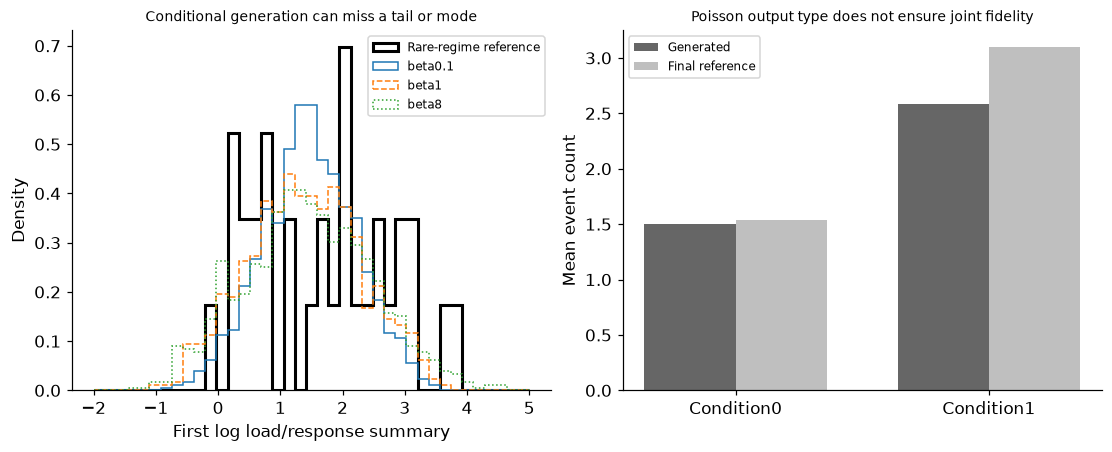

In [3]:
fig,axes=plt.subplots(1,2,figsize=(10,4));bins=np.linspace(-2,5,40);actual=final&(condition==1);axes[0].hist(continuous[actual,0],bins=bins,density=True,histtype='step',color='black',linewidth=2,label='Rare-regime reference')
for beta,style in zip(models,['-','--',':']):axes[0].hist(generated[beta][1][0][:,0],bins=bins,density=True,histtype='step',linestyle=style,label=f'beta{beta:g}')
axes[0].set(xlabel='First log load/response summary',ylabel='Density',title='Conditional generation can miss a tail or mode');axes[0].legend(fontsize=8);selected_rows=[r for r in coverage if r['beta']==selected_beta];xx=np.arange(2);axes[1].bar(xx-.18,[r['generated_count_mean'] for r in selected_rows],.36,color='.4',label='Generated');axes[1].bar(xx+.18,[r['reference_count_mean'] for r in selected_rows],.36,color='.75',label='Final reference');axes[1].set(xticks=xx,xticklabels=['Condition0','Condition1'],ylabel='Mean event count',title='Poisson output type does not ensure joint fidelity');axes[1].legend(fontsize=8);plt.show()
assert len(rows)==3 and all(np.isfinite(r['final_negative_ELBO_common_beta1']) for r in rows)


In [4]:
summary={'example_id':'code_139','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual reparameterized conditional VAE', 'Gaussian Bernoulli and Poisson decoder heads', 'common development ELBO comparison', 'per-latent KL and decoder sensitivity', 'conditional tail and type-valid generation'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
if 'resource_profile' in globals():summary['resource_observations']=resource_profile
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual reparameterized conditional VAE", "Gaussian Bernoulli and Poisson decoder heads", "common development ELBO comparison", "per-latent KL and decoder sensitivity", "conditional tail and type-valid generation"], "elapsed_seconds": 2.311, "example_id": "code_139", "hardware": "Darwin arm64 CPU", "results": {"building_counts": [50, 15, 15], "comparisons": [{"best_update": 500, "beta": 0.1, "decoder_latent_mean_variance_condition1": 0.5911475266049133, "development_negative_ELBO_common_beta1": 4.613809717678315, "final_KL_per_latent": [3.0005026384639404, 3.459203520110447], "final_negative_ELBO_common_beta1": 4.676657247346858, "parameters": 846}, {"best_update": 1050, "beta": 1.0, "decoder_latent_mean_variance_condition1": 0.8120883306590796, "development_negative_ELBO_common_beta1": 3.692331197327659, "final_KL_per_latent": [0.9734334138278707, 2.1198767555877036], "final_negative_ELBO_common_beta1": 3.7647639894767484, "parameters"